   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 225.7/225.7 kB 4.6 MB/s eta 0:00:00
  PRINT_LOG v1.0 | Miehle 40" 2 Couleurs | MODE=FAST
  Dataset : AI4I 2020 Predictive Maintenance (UCI ML Repository)
  Fenêtre : 80 obs | Test : cohen_d
  Seuil usure (hypothèse) : 60.0e percentile

Gradient d'usure : 30 points | Zone critique resserrée : 40–75e %ile

[1/6] Téléchargement AI4I 2020 (UCI ML Repository)...
[UCI] Téléchargement AI4I 2020...
  Colonnes disponibles : ['udi', 'product_id', 'type', 'air_temperature_k', 'process_temperature_k', 'rotational_speed_rpm', 'torque_nm', 'tool_wear_min', 'machine_failure', 'twf', 'hdf', 'pwf', 'osf', 'rnf']
  Observations : 10000

  Colonnes détectées :
    Tair=air_temperature_k | Tproc=process_temperature_k | RPM=rotational_speed_rpm | Couple=torque_nm | Usure=tool_wear_min | Panne=machine_failure

  10000 observations | 339 pannes détectées (3.4%)
  Usure outil : 0–253 min | Couple : 3.8–76.6 Nm | Vitesse : 1168–2886 rpm

[2/6] Extraction des 5 flux M

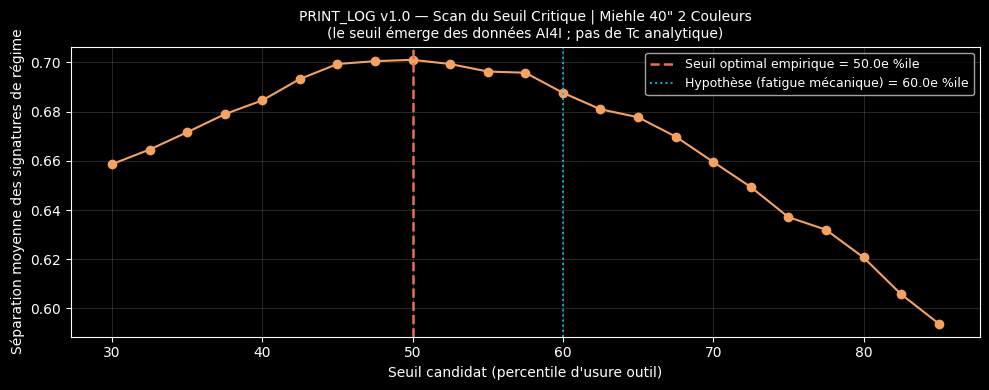


[Scan du seuil critique d'usure]
  Hypothèse (fatigue mécanique)  : 60.0e percentile
  Seuil optimal AI4I/Miehle       : 50.0e percentile (séparation = 0.701)

[4/6] Vue d'ensemble machine...


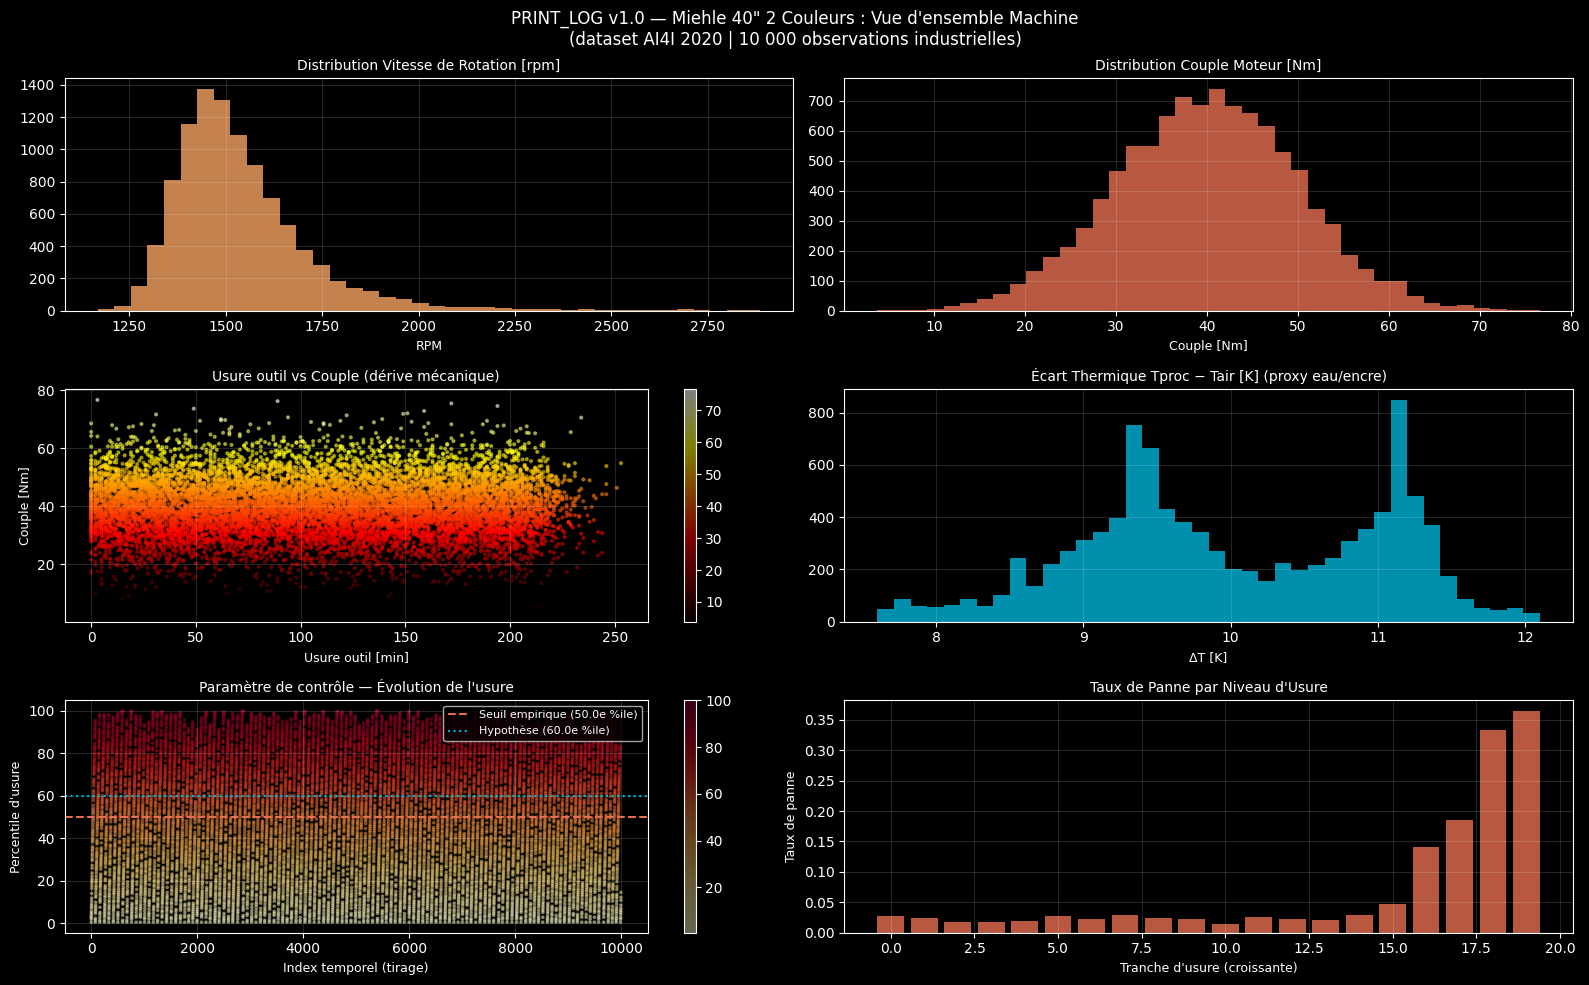

      Profils des 5 flux Miehle...


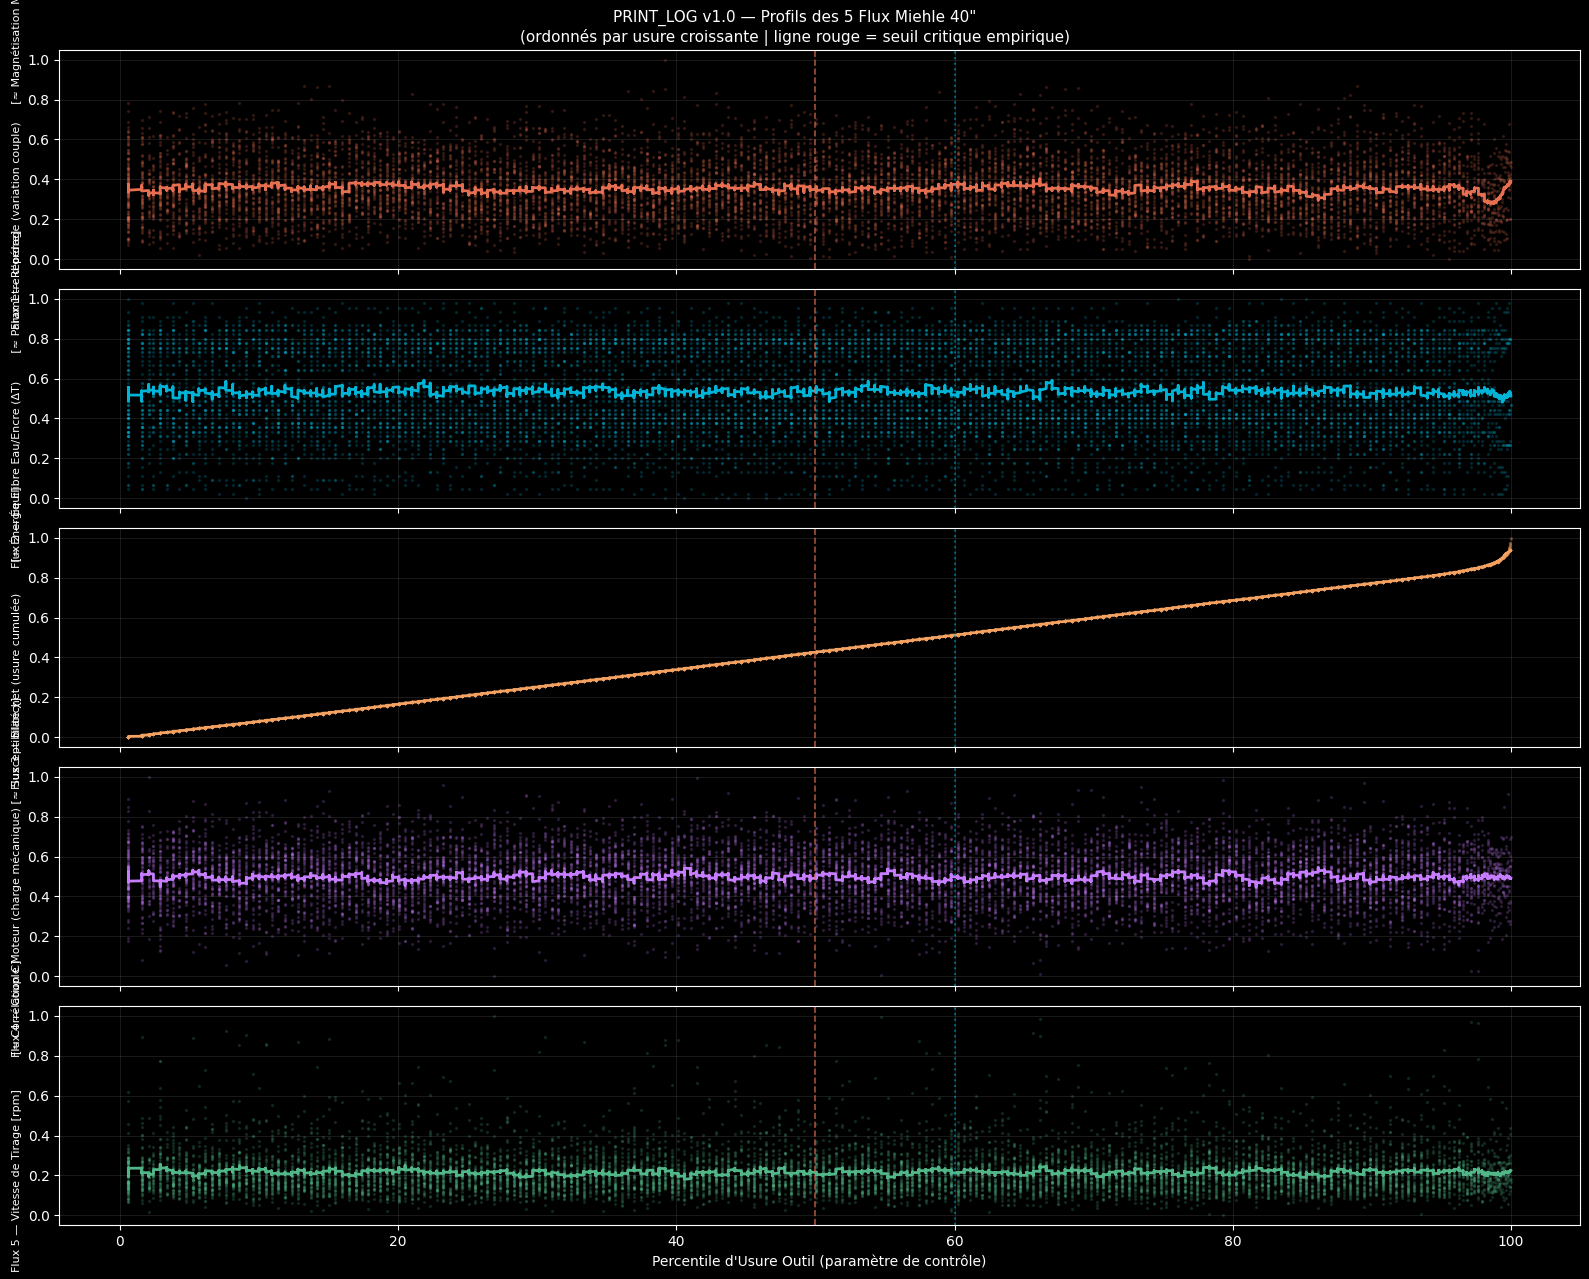


[5/6] Extraction des signatures de régime mécanique...

[Extraction] 1 fenêtre unique | Fenêtre=80 obs | 30 points de scan


Scan d'usure outil: 100%|██████████| 30/30 [23:28<00:00, 46.94s/it]


  Signatures extraites : 25
   Usure  N_fenetres  Reperage_Signal_Higuchi_mean  Reperage_Signal_DFA_mean  Reperage_Signal_Katz_mean  Reperage_Signal_Hurst_mean
0    5.0         597                      2.002849                  1.603033                  10.869988                    0.181014
1   10.0         597                      1.991254                  1.610731                   8.269532                    0.171637
2   15.0         601                      2.020551                  1.621334                  11.319652                    0.171614


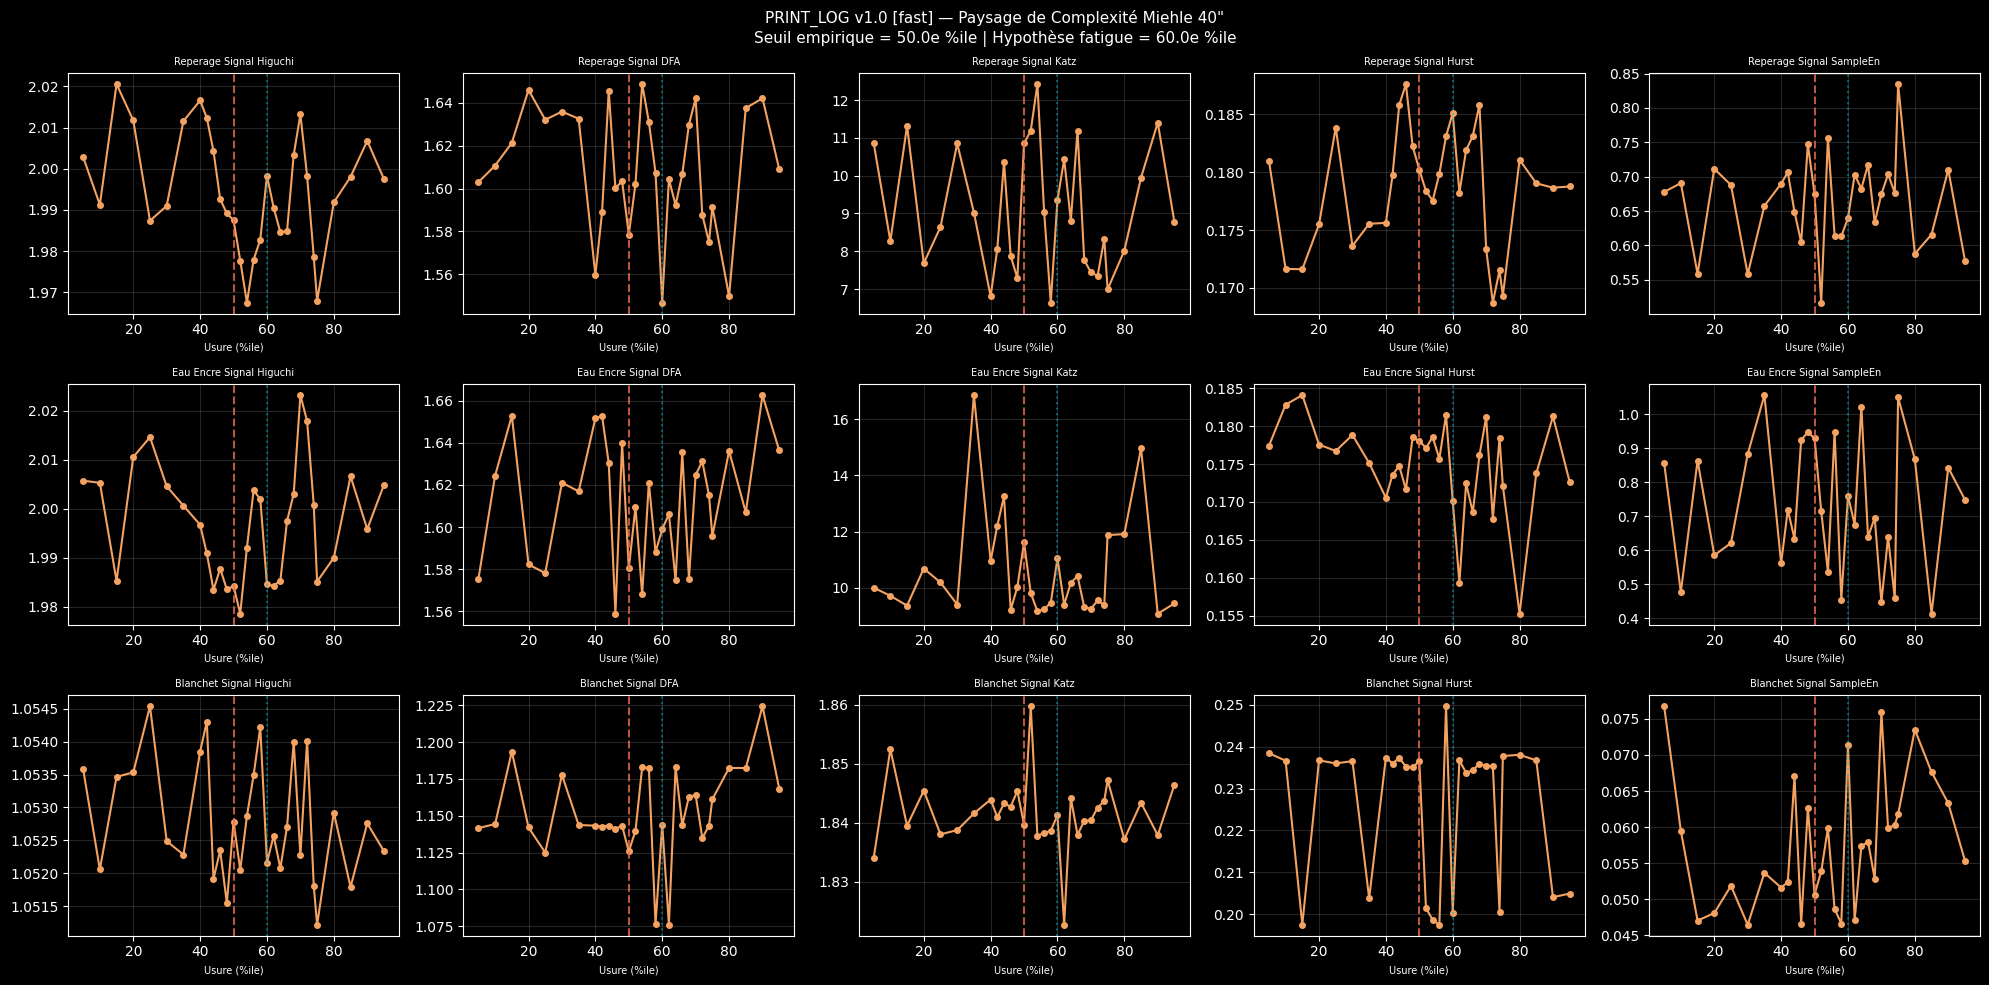


[6/6] 4 Questions presse Miehle...

=== 4 Questions Presse Miehle (seuil empirique = 50.0e %ile) ===
Q1 : Phase Nominale vs Phase Dégradée (presse neuve / presse usée)...
Q2 : Zone de Basculement Critique (Critical Slowing Down autour du seuil)...
Q3 : Dégradation Mécanique (Couple + Vitesse — engrenages / transmission)...
Q4 : Persistance de Régime (hystérésis mécanique intra-fenêtre)...

>>> RÉSULTATS — Scores de séparation des signatures de régime :
                                Q1_Nominal_vs_Degrade  Q2_Basculement_Critique  Q3_Degradation_Mecanique  Q4_Persistance_Regime
Blanchet_Signal_DFA_mean                        0.600                    0.051                       NaN                  2.716
Blanchet_Signal_Higuchi_mean                    1.020                    0.075                       NaN                  2.716
Blanchet_Signal_Hurst_mean                      0.370                    0.449                       NaN                  2.716
Blanchet_Signal_Katz_mean     

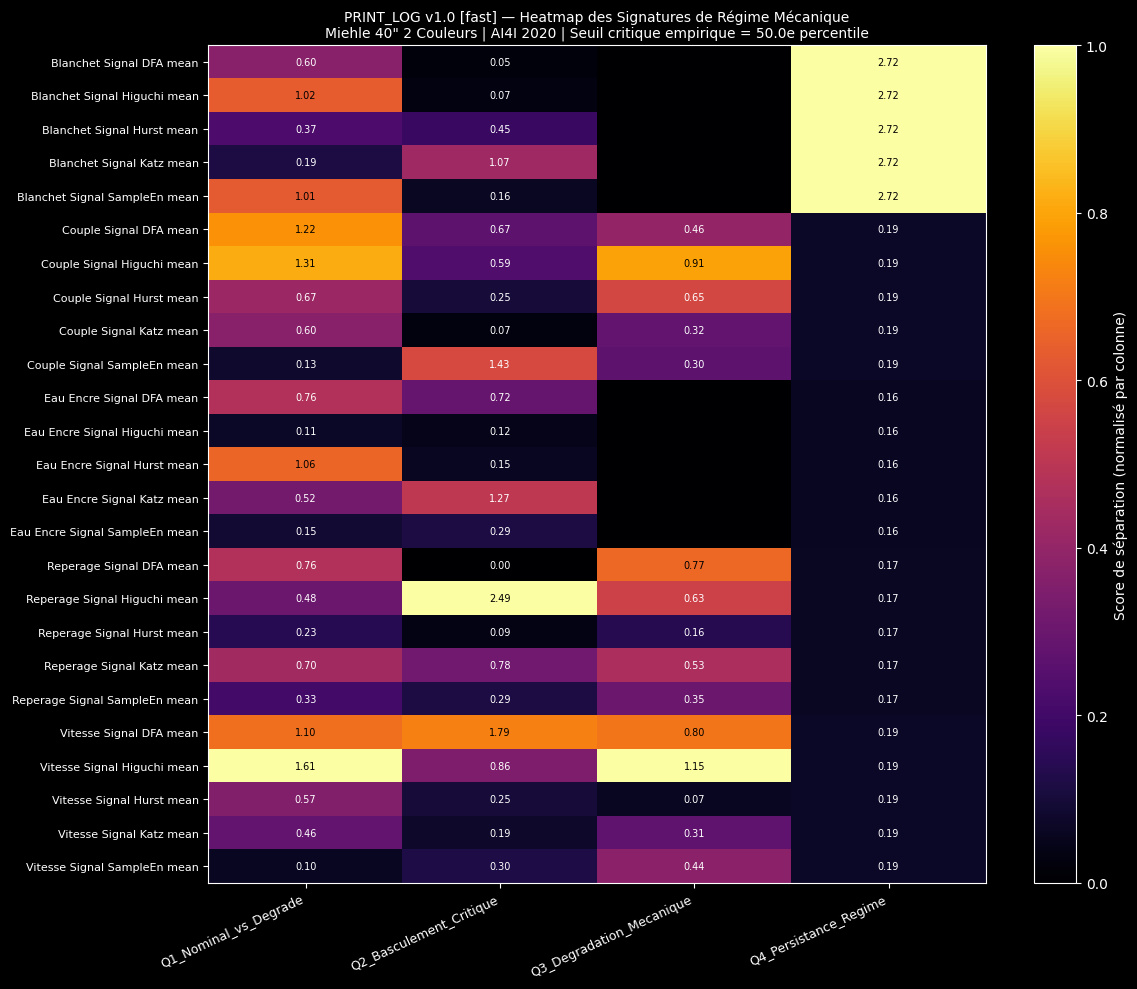


[OK] PRINT_LOG v1.0 terminé.
     10000 observations AI4I | Seuil critique empirique : 50.0e percentile
     (hypothèse fatigue mécanique = 60.0e percentile)


In [1]:
!pip install -q nolds antropy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
from scipy import stats
import requests, io
import warnings
warnings.filterwarnings('ignore')
import antropy, nolds

plt.style.use('dark_background')

# =============================================================================
# CONFIG
# =============================================================================

USURE_CRITIQUE_HYPOTHESE = 60.0   # 60e %ile d'usure outil ≈ zone de basculement
MODE = 'fast'                      # 'fast' | 'robust'

CONFIG = {
    'fast': {
        'n_estimations':   1,
        'window_size':     80,
        'stat_test':       'cohen_d',
        'min_per_group':   2,
        'estimator_min_len': 50,
        'mann_whitney':    False,
        'bootstrap':       False,
    },
    'robust': {
        'n_estimations':   5,
        'window_size':     150,
        'stat_test':       'cliff_delta',
        'min_per_group':   3,
        'estimator_min_len': 80,
        'mann_whitney':    True,
        'bootstrap':       True,
    }
}
C = CONFIG[MODE]

print("=" * 70)
print(f"  PRINT_LOG v1.0 | Miehle 40\" 2 Couleurs | MODE={MODE.upper()}")
print(f"  Dataset : AI4I 2020 Predictive Maintenance (UCI ML Repository)")
print(f"  Fenêtre : {C['window_size']} obs | Test : {C['stat_test']}")
print(f"  Seuil usure (hypothèse) : {USURE_CRITIQUE_HYPOTHESE}e percentile")
print("=" * 70)

# =============================================================================
# 0. STATISTIQUES
# =============================================================================

def cohen_d(g1, g2):
    g1, g2 = np.asarray(g1), np.asarray(g2)
    if len(g1) < 2 or len(g2) < 2: return np.nan
    ps = np.sqrt((np.var(g1, ddof=1) + np.var(g2, ddof=1)) / 2.0)
    return 0.0 if ps < 1e-12 else (np.mean(g1) - np.mean(g2)) / ps

def cliff_delta(g1, g2):
    g1, g2 = np.asarray(g1), np.asarray(g2)
    n1, n2 = len(g1), len(g2)
    if n1 < C['min_per_group'] or n2 < C['min_per_group']: return np.nan
    try:
        U, _ = stats.mannwhitneyu(g1, g2, alternative='two-sided')
        return np.clip((2 * U - n1 * n2) / (n1 * n2), -1, 1)
    except: return np.nan

def separation_score(g1, g2):
    if C['stat_test'] == 'cohen_d':
        d = cohen_d(g1, g2)
        return abs(d) if not np.isnan(d) else np.nan
    else:
        d = cliff_delta(g1, g2)
        return abs(d) if not np.isnan(d) else np.nan

# =============================================================================
# 1. ACQUISITION — AI4I 2020 (UCI)
# =============================================================================

def fetch_ai4i():
    """
    Télécharge le dataset AI4I 2020 depuis l'UCI ML Repository.
    10 000 observations, 14 variables : températures, vitesse, couple, usure, pannes.
    """
    URL = ("https://archive.ics.uci.edu/ml/machine-learning-databases"
           "/00601/ai4i2020.csv")
    print(f"[UCI] Téléchargement AI4I 2020...")
    try:
        resp = requests.get(URL, timeout=30)
        resp.raise_for_status()
        df = pd.read_csv(io.StringIO(resp.text))
    except Exception as e:
        print(f"  [Fallback] URL principale échouée ({e}), tentative miroir...")
        URL2 = ("https://raw.githubusercontent.com/jainrajat254/"
                "ML-Models/main/datasets/ai4i2020.csv")
        resp = requests.get(URL2, timeout=30)
        df = pd.read_csv(io.StringIO(resp.text))

    # Normalisation des noms de colonnes (espaces → underscore, tout minuscule)
    df.columns = [c.strip().lower().replace(' ','_').replace('[','').replace(']','')
                  .replace('/','_') for c in df.columns]

    print(f"  Colonnes disponibles : {list(df.columns)}")
    print(f"  Observations : {len(df)}")
    return df

def prepare_miehle(df):
    """
    Adapte le dataset AI4I à la Miehle 40" 2 couleurs :

    Paramètre de contrôle (axe de progression) :
        → Usure outil [min] = proxy de l'usure cumulative de la presse
          (blanchets, rouleaux, engrenages) au fil du tirage.

    5 Flux analogues Miehle :
        Flux 1 | Repérage_Signal     — Variance locale du couple (× vitesse)
                                        → micro-glissements entre groupe 1 et groupe 2
        Flux 2 | Eau_Encre_Signal    — Écart thermique Tprocess − Tair
                                        → équilibre chaleur / viscosité eau-encre
        Flux 3 | Blanchet_Signal     — Usure outil normalisée
                                        → déformation cumulative du blanchet caoutchouc
        Flux 4 | Couple_Signal       — Couple moteur normalisé [Nm]
                                        → charge mécanique sur les engrenages d'entraînement
        Flux 5 | Vitesse_Signal      — Vitesse de rotation normalisée [rpm]
                                        → cadence du tirage (feuilles/heure proxy)
    """
    # Détecter les colonnes clés (noms varient légèrement selon la source)
    def _find_col(df, candidates):
        for c in candidates:
            if c in df.columns: return c
        # recherche partielle
        for cand in candidates:
            matches = [col for col in df.columns if cand.split('_')[0] in col]
            if matches: return matches[0]
        return None

    col_air      = _find_col(df, ['air_temperature_k','air_temperature','airtemperature'])
    col_proc     = _find_col(df, ['process_temperature_k','process_temperature','processtemperature'])
    col_rpm      = _find_col(df, ['rotational_speed_rpm','rotational_speed','rotationalspeed'])
    col_torque   = _find_col(df, ['torque_nm','torque','torquenm'])
    col_wear     = _find_col(df, ['tool_wear_min','tool_wear','toolwear'])
    col_failure  = _find_col(df, ['machine_failure','machinefailure'])

    print(f"\n  Colonnes détectées :")
    print(f"    Tair={col_air} | Tproc={col_proc} | RPM={col_rpm} | "
          f"Couple={col_torque} | Usure={col_wear} | Panne={col_failure}")

    for c in [col_rpm, col_torque, col_wear]:
        if c is None: raise ValueError(f"Colonne introuvable dans : {list(df.columns)}")

    # Nettoyage
    out = df[[c for c in [col_air, col_proc, col_rpm, col_torque, col_wear,
                          col_failure] if c]].copy()
    out.columns = [
        'T_air', 'T_proc', 'rpm', 'torque', 'wear', 'failure'
    ][:len(out.columns)]
    for col in out.columns:
        out[col] = pd.to_numeric(out[col], errors='coerce')
    out = out.dropna(subset=['rpm','torque','wear']).reset_index(drop=True)

    # Feature engineering
    out['delta_T'] = out['T_proc'] - out['T_air']   # équilibre thermique eau/encre
    out['puissance'] = out['torque'] * (out['rpm'] * 2 * np.pi / 60)  # [W]

    def norm(s):
        mn, mx = s.min(), s.max()
        return (s - mn) / (mx - mn + 1e-12)

    out['wear_norm']   = norm(out['wear'])
    out['rpm_norm']    = norm(out['rpm'])
    out['torque_norm'] = norm(out['torque'])
    out['deltaT_norm'] = norm(out['delta_T'].fillna(out['delta_T'].median()))

    # Repérage : variation locale de couple (fenêtre glissante 5 pts)
    # Modélise les micro-glissements dans les pinces de transfert
    out['reperage_var'] = (out['torque']
                           .rolling(5, min_periods=1, center=True)
                           .std()
                           .fillna(0))
    out['reperage_norm'] = norm(out['reperage_var'])

    n_fail = out['failure'].sum() if 'failure' in out.columns else 0
    print(f"\n  {len(out)} observations | {int(n_fail)} pannes détectées "
          f"({100*n_fail/len(out):.1f}%)")
    print(f"  Usure outil : {out['wear'].min():.0f}–{out['wear'].max():.0f} min | "
          f"Couple : {out['torque'].min():.1f}–{out['torque'].max():.1f} Nm | "
          f"Vitesse : {out['rpm'].min():.0f}–{out['rpm'].max():.0f} rpm")
    return out

def extract_miehle_fluxes(df):
    """
    Les 5 flux Miehle mappés sur les analogies Ising.
    """
    return {
        'Reperage_Signal':  df['reperage_norm'].values,
        'Eau_Encre_Signal': df['deltaT_norm'].values,
        'Blanchet_Signal':  df['wear_norm'].values,
        'Couple_Signal':    df['torque_norm'].values,
        'Vitesse_Signal':   df['rpm_norm'].values,
    }

def compute_usure_level(df):
    """
    Paramètre de contrôle : percentile d'usure outil.
    0 = presse neuve → 100 = usure maximale avant déclassement.
    """
    wear = df['wear_norm'].values
    return np.array([stats.percentileofscore(wear, v) for v in wear])

# =============================================================================
# 2. SCAN DU SEUIL CRITIQUE
# =============================================================================

def scan_seuil_critique(df, fluxes, usure_series, candidats=None):
    if candidats is None:
        candidats = np.arange(30, 86, 2.5)

    W = C['window_size']
    flux_keys = list(fluxes.keys())
    n_obs = len(df)
    sort_idx = np.argsort(usure_series)
    usure_s  = usure_series[sort_idx]
    flux_s   = {k: v[sort_idx] for k, v in fluxes.items()}

    windows = []
    for i in range(n_obs - W + 1):
        windows.append({
            'usure': float(np.mean(usure_s[i:i+W])),
            'data':  {k: flux_s[k][i:i+W] for k in flux_keys}
        })

    if not windows:
        raise ValueError(f"Pas assez d'observations ({n_obs}) pour fenêtre={W}.")

    scores_par_seuil = []
    for seuil in candidats:
        g_bas  = [w for w in windows if w['usure'] <  seuil]
        g_haut = [w for w in windows if w['usure'] >= seuil]
        if len(g_bas) < C['min_per_group'] or len(g_haut) < C['min_per_group']:
            scores_par_seuil.append(np.nan); continue
        sep = []
        for k in flux_keys:
            d = separation_score(
                np.concatenate([w['data'][k] for w in g_bas]),
                np.concatenate([w['data'][k] for w in g_haut])
            )
            if not np.isnan(d): sep.append(d)
        scores_par_seuil.append(np.mean(sep) if sep else np.nan)

    scores_arr = np.array(scores_par_seuil, dtype=float)
    idx_max    = np.nanargmax(scores_arr)
    seuil_opt  = candidats[idx_max]

    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(candidats, scores_arr, 'o-', color='#f4a261', markersize=6)
    ax.axvline(seuil_opt, color='#e76f51', linestyle='--', linewidth=1.8,
               label=f'Seuil optimal empirique = {seuil_opt:.1f}e %ile')
    ax.axvline(USURE_CRITIQUE_HYPOTHESE, color='#00b4d8', linestyle=':', linewidth=1.4,
               label=f'Hypothèse (fatigue mécanique) = {USURE_CRITIQUE_HYPOTHESE}e %ile')
    ax.set_xlabel('Seuil candidat (percentile d\'usure outil)', fontsize=10)
    ax.set_ylabel('Séparation moyenne des signatures de régime', fontsize=10)
    ax.set_title(
        'PRINT_LOG v1.0 — Scan du Seuil Critique | Miehle 40" 2 Couleurs\n'
        '(le seuil émerge des données AI4I ; pas de Tc analytique)',
        fontsize=10)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.15)
    plt.tight_layout()
    plt.show()

    print(f"\n[Scan du seuil critique d'usure]")
    print(f"  Hypothèse (fatigue mécanique)  : {USURE_CRITIQUE_HYPOTHESE}e percentile")
    print(f"  Seuil optimal AI4I/Miehle       : {seuil_opt:.1f}e percentile "
          f"(séparation = {scores_arr[idx_max]:.3f})")
    return seuil_opt, candidats, scores_arr, windows

# =============================================================================
# 3. ESTIMATEURS DE COMPLEXITÉ
# =============================================================================

def apply_estimators(series, flux_name=''):
    s = np.asarray(series).flatten()
    min_len = C['estimator_min_len']
    if len(s) < min_len:
        return {k: np.nan for k in ['Higuchi','DFA','Katz','Hurst','SampleEn']}
    if np.std(s) > 1e-10:
        s = (s - np.mean(s)) / np.std(s)
    if len(s) < min_len:
        return {k: np.nan for k in ['Higuchi','DFA','Katz','Hurst','SampleEn']}
    est = {}
    try: est['Higuchi']  = antropy.higuchi_fd(s)
    except: est['Higuchi'] = np.nan
    try: est['DFA']      = 2.0 - nolds.dfa(s)
    except: est['DFA'] = np.nan
    try: est['Katz']     = antropy.katz_fd(s)
    except: est['Katz'] = np.nan
    try: est['Hurst']    = nolds.hurst_rs(s)
    except: est['Hurst'] = np.nan
    try: est['SampleEn'] = antropy.sample_entropy(s[:min(500,len(s))], order=2)
    except: est['SampleEn'] = np.nan
    return est

# =============================================================================
# 4. PIPELINE
# =============================================================================

def build_miehle_features(df, fluxes, usure_series, usure_scan):
    W  = C['window_size']
    n  = C['n_estimations']
    tol = max(3.0, (usure_scan[1]-usure_scan[0])/2.0) if len(usure_scan)>1 else 3.0

    sort_idx    = np.argsort(usure_series)
    usure_s     = usure_series[sort_idx]
    flux_sorted = {k: v[sort_idx] for k, v in fluxes.items()}
    flux_keys   = list(fluxes.keys())
    n_obs       = len(df)

    window_data = []
    for i in range(n_obs - W + 1):
        window_data.append({
            'usure': float(np.mean(usure_s[i:i+W])),
            'fluxes': {k: flux_sorted[k][i:i+W] for k in flux_keys}
        })

    mode_label = ("bootstrap" if C['bootstrap'] else "fenêtre unique")
    print(f"\n[Extraction] {n} {mode_label} | Fenêtre={W} obs | "
          f"{len(usure_scan)} points de scan")

    rows = []
    for P in tqdm(usure_scan, desc="Scan d'usure outil"):
        matching = [w for w in window_data if abs(w['usure'] - P) <= tol]
        if not matching:
            matching = [min(window_data, key=lambda w: abs(w['usure'] - P))]
        row = {'Usure': P, 'N_fenetres': len(matching)}

        for flux in flux_keys:
            if n == 1:
                combined = np.concatenate([w['fluxes'][flux] for w in matching])
                ests = apply_estimators(combined, flux_name=flux)
                for k, v in ests.items():
                    row[f"{flux}_{k}_mean"] = v
            else:
                rng = np.random.default_rng(42)
                feat_vals = {nm: [] for nm in ['Higuchi','DFA','Katz','Hurst','SampleEn']}
                for _ in range(n):
                    idx = rng.choice(len(matching), size=max(1,len(matching)//2), replace=True)
                    sub = np.concatenate([matching[i]['fluxes'][flux] for i in idx])
                    ests = apply_estimators(sub, flux_name=flux)
                    for k, v in ests.items():
                        if not np.isnan(v): feat_vals[k].append(v)
                for k, vals in feat_vals.items():
                    if vals:
                        row[f"{flux}_{k}_mean"] = np.mean(vals)
                        row[f"{flux}_{k}_std"]  = np.std(vals,ddof=1) if len(vals)>1 else np.nan
                    else:
                        row[f"{flux}_{k}_mean"] = np.nan
                        row[f"{flux}_{k}_std"]  = np.nan
        rows.append(row)

    df_feat = pd.DataFrame(rows)
    feature_cols = [c for c in df_feat.columns
                    if c not in ['Usure','N_fenetres'] and not c.endswith('_std')]
    return df_feat, feature_cols, window_data

# =============================================================================
# 5. LES 4 QUESTIONS PRESSE MIEHLE
# =============================================================================

def compare_groups(df_feat, feature_cols, g_low, g_high, label=''):
    grp_bas  = df_feat[df_feat['Usure'].between(g_low[0],  g_low[1])]
    grp_haut = df_feat[df_feat['Usure'].between(g_high[0], g_high[1])]
    if len(grp_bas) < C['min_per_group'] or len(grp_haut) < C['min_per_group']:
        print(f"  [!] {label} : groupes trop petits ({len(grp_bas)}/{len(grp_haut)})")
    scores = {}
    for col in feature_cols:
        if col not in df_feat.columns: continue
        v1 = grp_bas[col].dropna().values
        v2 = grp_haut[col].dropna().values
        if len(v1) >= C['min_per_group'] and len(v2) >= C['min_per_group']:
            scores[col] = separation_score(v1, v2)
    return pd.Series(scores)

def run_miehle_questions(df_feat, feature_cols, window_data, seuil):
    print(f"\n=== 4 Questions Presse Miehle (seuil empirique = {seuil:.1f}e %ile) ===")
    r = {}

    # Q1 — Presse neuve vs presse usée
    print("Q1 : Phase Nominale vs Phase Dégradée (presse neuve / presse usée)...")
    r["Q1_Nominal_vs_Degrade"] = compare_groups(
        df_feat, feature_cols, [0, 30], [70, 100], "Q1")

    # Q2 — Zone de basculement (critical slowing down)
    print("Q2 : Zone de Basculement Critique (Critical Slowing Down autour du seuil)...")
    marge = 8.0
    r["Q2_Basculement_Critique"] = compare_groups(
        df_feat, feature_cols,
        [seuil - 2*marge, seuil - marge*0.3],
        [seuil + marge*0.3, seuil + 2*marge],
        "Q2"
    )

    # Q3 — Signature mécanique (couple + vitesse)
    print("Q3 : Dégradation Mécanique (Couple + Vitesse — engrenages / transmission)...")
    meca_cols = [c for c in feature_cols
                 if any(x in c for x in ['Couple_Signal','Vitesse_Signal','Reperage_Signal'])]
    r["Q3_Degradation_Mecanique"] = compare_groups(
        df_feat, meca_cols if meca_cols else feature_cols,
        [0, 35], [65, 100], "Q3")

    # Q4 — Hystérésis intra-fenêtre (persistance de régime)
    print("Q4 : Persistance de Régime (hystérésis mécanique intra-fenêtre)...")
    flux_names = ['Reperage_Signal','Eau_Encre_Signal','Blanchet_Signal',
                  'Couple_Signal','Vitesse_Signal']
    q4 = {}
    for col in feature_cols:
        flux = next((f for f in flux_names if col.startswith(f)), None)
        if flux is None: continue
        effects = []
        for w in window_data:
            s = w['fluxes'].get(flux)
            if s is None or len(s) < 20: continue
            mid = len(s) // 2
            d = separation_score(s[:mid], s[mid:])
            if not np.isnan(d): effects.append(abs(d))
        q4[col] = np.mean(effects) if effects else np.nan
    r["Q4_Persistance_Regime"] = pd.Series(q4)

    return pd.DataFrame({k: v.round(3) for k, v in r.items()}), r

# =============================================================================
# 6. VISUALISATION
# =============================================================================

ORANGE = '#f4a261'
RED    = '#e76f51'
BLUE   = '#00b4d8'
GREEN  = '#52b788'
PURPLE = '#c77dff'
YELLOW = '#ffd60a'

def plot_machine_overview(df, usure_series, seuil):
    fig, axes = plt.subplots(3, 2, figsize=(16, 10))

    # RPM distribution
    axes[0,0].hist(df['rpm'], bins=40, color=ORANGE, alpha=0.8)
    axes[0,0].set_title('Distribution Vitesse de Rotation [rpm]', fontsize=10)
    axes[0,0].set_xlabel('RPM', fontsize=9)
    axes[0,0].grid(True, alpha=0.15)

    # Couple distribution
    axes[0,1].hist(df['torque'], bins=40, color=RED, alpha=0.8)
    axes[0,1].set_title('Distribution Couple Moteur [Nm]', fontsize=10)
    axes[0,1].set_xlabel('Couple [Nm]', fontsize=9)
    axes[0,1].grid(True, alpha=0.15)

    # Usure vs Couple
    sc = axes[1,0].scatter(df['wear'], df['torque'],
                           c=df['torque'], cmap='hot', s=4, alpha=0.5)
    axes[1,0].set_xlabel('Usure outil [min]', fontsize=9)
    axes[1,0].set_ylabel('Couple [Nm]', fontsize=9)
    axes[1,0].set_title('Usure outil vs Couple (dérive mécanique)', fontsize=10)
    plt.colorbar(sc, ax=axes[1,0])
    axes[1,0].grid(True, alpha=0.15)

    # Delta T distribution
    if 'delta_T' in df.columns:
        axes[1,1].hist(df['delta_T'].dropna(), bins=40, color=BLUE, alpha=0.8)
        axes[1,1].set_title('Écart Thermique Tproc − Tair [K] (proxy eau/encre)', fontsize=10)
        axes[1,1].set_xlabel('ΔT [K]', fontsize=9)
        axes[1,1].grid(True, alpha=0.15)
    else:
        axes[1,1].text(0.5,0.5,'ΔT non disponible',ha='center',va='center',
                       transform=axes[1,1].transAxes, color='gray')

    # Progression vs Usure
    sc2 = axes[2,0].scatter(df.index, usure_series, c=usure_series, cmap='YlOrRd', s=3, alpha=0.4)
    axes[2,0].axhline(seuil, color=RED, linestyle='--', linewidth=1.5,
                      label=f'Seuil empirique ({seuil:.1f}e %ile)')
    axes[2,0].axhline(USURE_CRITIQUE_HYPOTHESE, color=BLUE, linestyle=':',
                      label=f'Hypothèse ({USURE_CRITIQUE_HYPOTHESE}e %ile)')
    axes[2,0].set_xlabel('Index temporel (tirage)', fontsize=9)
    axes[2,0].set_ylabel('Percentile d\'usure', fontsize=9)
    axes[2,0].set_title('Paramètre de contrôle — Évolution de l\'usure', fontsize=10)
    axes[2,0].legend(fontsize=8)
    axes[2,0].grid(True, alpha=0.15)
    plt.colorbar(sc2, ax=axes[2,0])

    # Pannes
    if 'failure' in df.columns:
        fail_by_usure = df.groupby(pd.cut(df['wear_norm'], bins=20))['failure'].mean()
        axes[2,1].bar(range(len(fail_by_usure)), fail_by_usure.values, color=RED, alpha=0.8)
        axes[2,1].set_xlabel('Tranche d\'usure (croissante)', fontsize=9)
        axes[2,1].set_ylabel('Taux de panne', fontsize=9)
        axes[2,1].set_title('Taux de Panne par Niveau d\'Usure', fontsize=10)
        axes[2,1].grid(True, alpha=0.15)
    else:
        axes[2,1].text(0.5,0.5,'Données de panne non disponibles',
                       ha='center',va='center',transform=axes[2,1].transAxes, color='gray')

    plt.suptitle('PRINT_LOG v1.0 — Miehle 40" 2 Couleurs : Vue d\'ensemble Machine\n'
                 '(dataset AI4I 2020 | 10 000 observations industrielles)', fontsize=12)
    plt.tight_layout()
    plt.show()

def plot_flux_profiles(df, fluxes, usure_series, seuil):
    sort_idx = np.argsort(usure_series)
    usure_s  = usure_series[sort_idx]

    flux_meta = [
        ('Reperage_Signal',  RED,    'Flux 1 — Repérage (variation couple)     [≈ Magnétisation M]'),
        ('Eau_Encre_Signal', BLUE,   'Flux 2 — Équilibre Eau/Encre (ΔT)        [≈ Paramètre d\'ordre]'),
        ('Blanchet_Signal',  ORANGE, 'Flux 3 — Blanchet (usure cumulée)         [≈ Énergie E]'),
        ('Couple_Signal',    PURPLE, 'Flux 4 — Couple Moteur (charge mécanique) [≈ Susceptibilité χ]'),
        ('Vitesse_Signal',   GREEN,  'Flux 5 — Vitesse de Tirage [rpm]          [≈ Corrélation C]'),
    ]
    fig, axes = plt.subplots(5, 1, figsize=(16, 13), sharex=True)
    for ax, (flux, color, label) in zip(axes, flux_meta):
        vals   = fluxes[flux][sort_idx]
        smooth = pd.Series(vals).rolling(80, min_periods=10, center=True).mean()
        ax.scatter(usure_s, vals, color=color, s=2, alpha=0.15)
        ax.plot(usure_s, smooth, color=color, linewidth=2.0)
        ax.axvline(seuil, color=RED, linestyle='--', alpha=0.7, linewidth=1.2)
        ax.axvline(USURE_CRITIQUE_HYPOTHESE, color=BLUE, linestyle=':', alpha=0.5)
        ax.set_ylabel(label, fontsize=8)
        ax.grid(True, alpha=0.1)
    axes[-1].set_xlabel('Percentile d\'Usure Outil (paramètre de contrôle)', fontsize=10)
    plt.suptitle('PRINT_LOG v1.0 — Profils des 5 Flux Miehle 40"\n'
                 '(ordonnés par usure croissante | ligne rouge = seuil critique empirique)',
                 fontsize=11)
    plt.tight_layout()
    plt.show()

def plot_landscape(df_feat, seuil):
    mean_cols = [c for c in df_feat.columns if c.endswith('_mean')]
    n = min(len(mean_cols), 15)
    fig, axes = plt.subplots(3, 5, figsize=(20, 10))
    axes = axes.flatten()
    for i, col in enumerate(mean_cols[:n]):
        ax = axes[i]
        ax.plot(df_feat['Usure'], df_feat[col], 'o-', color=ORANGE, markersize=4)
        std_col = col.replace('_mean','_std')
        if std_col in df_feat.columns:
            ax.fill_between(df_feat['Usure'],
                            df_feat[col]-df_feat[std_col],
                            df_feat[col]+df_feat[std_col],
                            alpha=0.25, color=ORANGE)
        ax.axvline(seuil, color=RED, linestyle='--', alpha=0.8)
        ax.axvline(USURE_CRITIQUE_HYPOTHESE, color=BLUE, linestyle=':', alpha=0.5)
        ax.set_title(col.replace('_mean','').replace('_',' '), fontsize=7)
        ax.set_xlabel('Usure (%ile)', fontsize=7)
        ax.grid(True, alpha=0.15)
    for j in range(n, len(axes)):
        axes[j].set_visible(False)
    plt.suptitle(
        f"PRINT_LOG v1.0 [{MODE}] — Paysage de Complexité Miehle 40\"\n"
        f"Seuil empirique = {seuil:.1f}e %ile | "
        f"Hypothèse fatigue = {USURE_CRITIQUE_HYPOTHESE}e %ile",
        fontsize=11)
    plt.tight_layout()
    plt.show()

def plot_heatmap(summary, seuil):
    fig, ax = plt.subplots(figsize=(12, max(5, len(summary)*0.4)))
    data = summary.fillna(0).copy()
    for c in data.columns:
        m = data[c].max()
        if m > 0: data[c] /= m
    im = ax.imshow(data.values, aspect='auto', cmap='inferno', vmin=0, vmax=1)
    ax.set_xticks(range(len(data.columns)))
    ax.set_xticklabels(data.columns, rotation=25, ha='right', fontsize=9)
    ax.set_yticks(range(len(data.index)))
    ax.set_yticklabels([idx.replace('_',' ') for idx in data.index], fontsize=8)
    for i in range(len(data.index)):
        for j in range(len(data.columns)):
            v = summary.iloc[i, j]
            if not np.isnan(v):
                ax.text(j, i, f"{v:.2f}", ha='center', va='center',
                        color='black' if data.iloc[i,j]>0.6 else 'white', fontsize=7)
    plt.colorbar(im, ax=ax, label='Score de séparation (normalisé par colonne)')
    plt.title(
        f"PRINT_LOG v1.0 [{MODE}] — Heatmap des Signatures de Régime Mécanique\n"
        f"Miehle 40\" 2 Couleurs | AI4I 2020 | "
        f"Seuil critique empirique = {seuil:.1f}e percentile",
        fontsize=10)
    plt.tight_layout()
    plt.show()

# =============================================================================
# 7. EXÉCUTION PRINCIPALE
# =============================================================================

USURE_SCAN = np.round(np.concatenate([
    np.arange(5,  40, 5.0),   # régime nominal
    np.arange(40, 75, 2.0),   # zone critique (résolution fine)
    np.arange(75, 96, 5.0)    # régime dégradé
]), 1)

print(f"\nGradient d'usure : {len(USURE_SCAN)} points | "
      f"Zone critique resserrée : 40–75e %ile")
print("=" * 70)

# --- 1. Données ---
print("\n[1/6] Téléchargement AI4I 2020 (UCI ML Repository)...")
df_raw  = fetch_ai4i()
df      = prepare_miehle(df_raw)

# --- 2. Flux & paramètre de contrôle ---
print("\n[2/6] Extraction des 5 flux Miehle & du paramètre d'usure...")
fluxes       = extract_miehle_fluxes(df)
usure_series = compute_usure_level(df)
print(f"  Usure (percentile) : min={usure_series.min():.1f} | "
      f"max={usure_series.max():.1f} | mean={usure_series.mean():.1f}")

# --- 3. Scan du seuil ---
print("\n[3/6] Scan du seuil critique (30–85e percentile)...")
seuil_opt, candidats_scan, scores_scan, windows_scan = \
    scan_seuil_critique(df, fluxes, usure_series)
USURE_CRITIQUE = seuil_opt

# --- 4. Vue d'ensemble ---
print("\n[4/6] Vue d'ensemble machine...")
plot_machine_overview(df, usure_series, USURE_CRITIQUE)
print("      Profils des 5 flux Miehle...")
plot_flux_profiles(df, fluxes, usure_series, USURE_CRITIQUE)

# --- 5. Signatures de régime ---
print("\n[5/6] Extraction des signatures de régime mécanique...")
df_feat, feature_cols, window_data = build_miehle_features(
    df, fluxes, usure_series, USURE_SCAN)
print(f"  Signatures extraites : {len(feature_cols)}")
print(df_feat[['Usure','N_fenetres']+feature_cols[:4]].head(3).to_string())
plot_landscape(df_feat, USURE_CRITIQUE)

# --- 6. 4 Questions ---
print("\n[6/6] 4 Questions presse Miehle...")
summary, results = run_miehle_questions(
    df_feat, feature_cols, window_data, USURE_CRITIQUE)
print("\n>>> RÉSULTATS — Scores de séparation des signatures de régime :")
print(summary.to_string())

print("\n>>> TOP 3 PAR QUESTION :")
for q in summary.columns:
    top = summary[q].dropna().sort_values(ascending=False).head(3)
    if len(top):
        print(f"\n  [{q}]")
        for f, v in top.items():
            print(f"    {f.replace('_mean',''):46s} : {v:.3f}")

plot_heatmap(summary, USURE_CRITIQUE)

print(f"\n[OK] PRINT_LOG v1.0 terminé.")
print(f"     {len(df)} observations AI4I | Seuil critique empirique : {USURE_CRITIQUE:.1f}e percentile")
print(f"     (hypothèse fatigue mécanique = {USURE_CRITIQUE_HYPOTHESE}e percentile)")